In [2]:
import pandas as pd
import numpy as np
import os
import sys

## Load raw datas

In [3]:
Dataset_path = './Dataset/20260306 Readout_MRI_2times_Final.xlsx'
Data = pd.read_excel(Dataset_path)
print(Data.columns)

Index(['ID', 'Name', 'Sex', 'Age', 'Chronicity_Onset', 'Onset_to_FirstVisit',
       'Treatment_Duration', 'Onset_to_Completion', 'Chronicity_Completion',
       '1_PainSide_Rt1Lt2Both3', '1_CMO', '1_VAS', '2_VAS', 'VAS_Improvement',
       '1_CMI', '2_CMI', '1_TMJnoise', '1_TMJpain', '1_MuscleStiffness',
       '1_TMJLocking', '1_Tinnitus', '1_Bruxism', '1_PsychologicalStress',
       '1_SleepProblems', '1_Headache', '1_Caffeine', '1_Rt_ADDWO',
       '1_Lt_ADDWO', '2_Rt_ADDWO', '2_Lt_ADDWO', '1_Rt_Effusion',
       '1_Lt_Effusion', '2_Rt_Effusion', '2_Lt_Effusion', '1_Rt_TMJOA',
       '1_Lt_TMJOA', '2_Rt_TMJOA', '2_Lt_TMJOA', 'MRI_Aggrevation'],
      dtype='object')


## Mapping alphabet to column names

In [7]:
import string

# 교수님의 실제 데이터 칼럼 리스트
cols = ['ID', 'Name', 'Sex', 'Age', 'Chronicity_Onset', 'Onset_to_FirstVisit',
       'Treatment_Duration', 'Onset_to_Completion', 'Chronicity_Completion',
       '1_PainSide_Rt1Lt2Both3', '1_CMO', '1_VAS', '2_VAS', 'VAS_Improvement',
       '1_CMI', '2_CMI', '1_TMJnoise', '1_TMJpain', '1_MuscleStiffness',
       '1_TMJLocking', '1_Tinnitus', '1_Bruxism', '1_PsychologicalStress',
       '1_SleepProblems', '1_Headache', '1_Caffeine', '1_Rt_ADDWO',
       '1_Lt_ADDWO', '2_Rt_ADDWO', '2_Lt_ADDWO', '1_Rt_Effusion',
       '1_Lt_Effusion', '2_Rt_Effusion', '2_Lt_Effusion', '1_Rt_TMJOA',
       '1_Lt_TMJOA', '2_Rt_TMJOA', '2_Lt_TMJOA', 'MRI_Aggrevation']

# 엑셀 알파벳 리스트 만들기 (A~Z, AA~AZ)
alphabet = list(string.ascii_uppercase)
excel_cols = alphabet + ['A' + a for a in alphabet]

# 알파벳과 칼럼명 짝지어서 출력하기
print("-" * 40)
print(f"{'엑셀 열':<10} | {'파이썬 칼럼명'}")
print("-" * 40)

for i, col_name in enumerate(cols):
    print(f"[{excel_cols[i]}]열{'':<5} | {col_name}")
print("-" * 40)

----------------------------------------
엑셀 열       | 파이썬 칼럼명
----------------------------------------
[A]열      | ID
[B]열      | Name
[C]열      | Sex
[D]열      | Age
[E]열      | Chronicity_Onset
[F]열      | Onset_to_FirstVisit
[G]열      | Treatment_Duration
[H]열      | Onset_to_Completion
[I]열      | Chronicity_Completion
[J]열      | 1_PainSide_Rt1Lt2Both3
[K]열      | 1_CMO
[L]열      | 1_VAS
[M]열      | 2_VAS
[N]열      | VAS_Improvement
[O]열      | 1_CMI
[P]열      | 2_CMI
[Q]열      | 1_TMJnoise
[R]열      | 1_TMJpain
[S]열      | 1_MuscleStiffness
[T]열      | 1_TMJLocking
[U]열      | 1_Tinnitus
[V]열      | 1_Bruxism
[W]열      | 1_PsychologicalStress
[X]열      | 1_SleepProblems
[Y]열      | 1_Headache
[Z]열      | 1_Caffeine
[AA]열      | 1_Rt_ADDWO
[AB]열      | 1_Lt_ADDWO
[AC]열      | 2_Rt_ADDWO
[AD]열      | 2_Lt_ADDWO
[AE]열      | 1_Rt_Effusion
[AF]열      | 1_Lt_Effusion
[AG]열      | 2_Rt_Effusion
[AH]열      | 2_Lt_Effusion
[AI]열      | 1_Rt_TMJOA
[AJ]열      | 1_Lt_TMJOA
[AK]열      | 2_Rt

## Delete I, N, M Columns and name column, and ID

In [4]:
# 분석에서 완전히 배제할 3개의 열 삭제
columns_to_drop = ['Chronicity_Completion', 'VAS_Improvement', 'MRI_Aggrevation', 'Name', 'ID', '2_VAS', '2_CMI', '2_Rt_ADDWO', '2_Lt_ADDWO', '2_Rt_Effusion', '2_Lt_Effusion', '2_Rt_TMJOA', '2_Lt_TMJOA']
#Data = Data.drop(columns=columns_to_drop)

## 결측치 확인

In [10]:
Data.info()
print("\n" + "="*40 + "\n")
print("🔍 [각 칼럼별 결측치(NaN) 개수 확인]")
nan_counts = Data.isnull().sum()
nan_counts_only = nan_counts[nan_counts > 0]

if len(nan_counts_only) == 0:
    print("🎉 결측치가 하나도 없습니다! 아주 깨끗한 데이터입니다.")
else:
    print(nan_counts_only)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 39 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      89 non-null     int64  
 1   Name                    89 non-null     object 
 2   Sex                     89 non-null     int64  
 3   Age                     89 non-null     int64  
 4   Chronicity_Onset        89 non-null     int64  
 5   Onset_to_FirstVisit     89 non-null     float64
 6   Treatment_Duration      89 non-null     float64
 7   Onset_to_Completion     89 non-null     float64
 8   Chronicity_Completion   89 non-null     int64  
 9   1_PainSide_Rt1Lt2Both3  89 non-null     int64  
 10  1_CMO                   89 non-null     float64
 11  1_VAS                   89 non-null     float64
 12  2_VAS                   89 non-null     int64  
 13  VAS_Improvement         89 non-null     int64  
 14  1_CMI                   89 non-null     floa

## Correlation analysis (1_VAS <> features), comparison based on chronic onset

상태: 1_VAS 분석을 시작합니다.
결과 변수 (Target): 1_VAS
비교 분석할 변수 목록 (Total: 25개):
[Sex, Age, Chronicity_Onset, Onset_to_FirstVisit, Treatment_Duration, Onset_to_Completion, 1_PainSide_Rt1Lt2Both3, 1_CMO, 1_CMI, 1_TMJnoise, 1_TMJpain, 1_MuscleStiffness, 1_TMJLocking, 1_Tinnitus, 1_Bruxism, 1_PsychologicalStress, 1_SleepProblems, 1_Headache, 1_Caffeine, 1_Rt_ADDWO, 1_Lt_ADDWO, 1_Rt_Effusion, 1_Lt_Effusion, 1_Rt_TMJOA, 1_Lt_TMJOA]


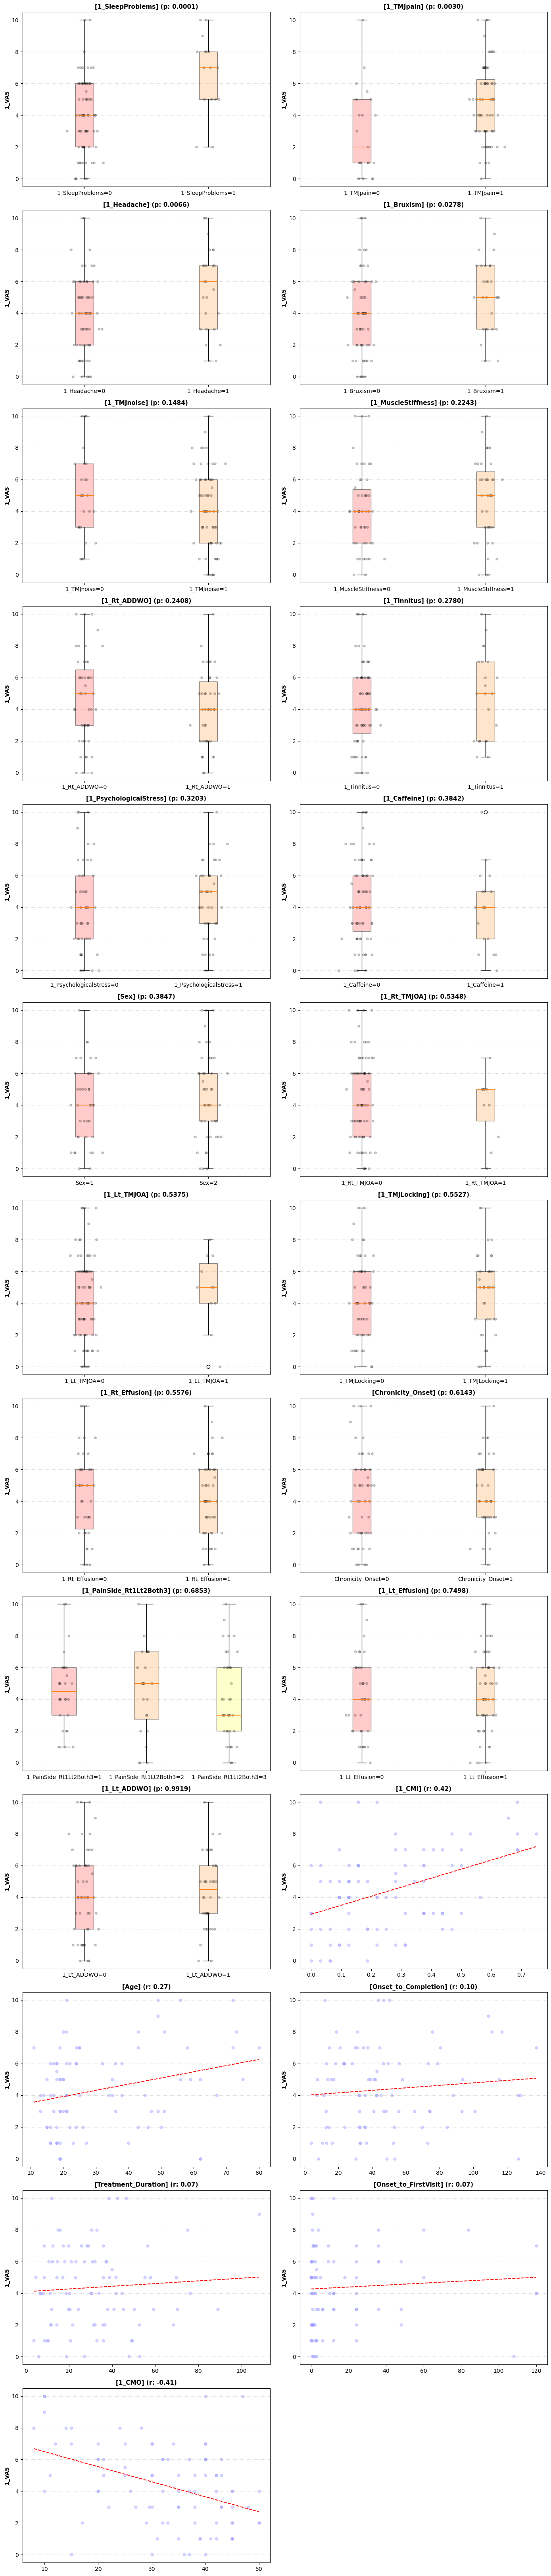

/home/bis/anaconda3/envs/JSG_openfold/lib/python3.7/site-packages/scipy/stats/stats.py:4023: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())




,Feature,Correlation,p_value,Method
16,1_SleepProblems,0.411822,0.000061,Group
10,1_TMJpain,0.310760,0.003037,Group
17,1_Headache,0.285818,0.006624,Group
14,1_Bruxism,0.233351,0.027751,Group
9,1_TMJnoise,-0.154445,0.148425,Group
11,1_MuscleStiffness,0.130094,0.224318,Group
19,1_Rt_ADDWO,-0.125609,0.240837,Group
13,1_Tinnitus,0.116254,0.277957,Group
15,1_PsychologicalStress,0.106561,0.320263,Group
18,1_Caffeine,-0.093348,0.384249,Group


,Feature,Method,p0,p1,Diff,r0,r1
19,1_Rt_ADDWO,Group,0.171903,0.890012,0.718109,NaN,NaN
0,Sex,Group,0.889618,0.184141,0.705477,NaN,NaN
24,1_Lt_TMJOA,Group,0.704796,0.125512,0.579284,NaN,NaN
12,1_TMJLocking,Group,0.506179,0.994161,0.487982,NaN,NaN
18,1_Caffeine,Group,0.413988,0.897209,0.483221,NaN,NaN
6,1_PainSide_Rt1Lt2Both3,Group,0.693027,0.270898,0.422129,NaN,NaN
23,1_Rt_TMJOA,Group,0.499656,0.914028,0.414372,NaN,NaN
13,1_Tinnitus,Group,0.624644,0.232874,0.391770,NaN,NaN
9,1_TMJnoise,Group,0.392463,0.087043,0.305420,NaN,NaN
11,1_MuscleStiffness,Group,0.526994,0.224825,0.302169,NaN,NaN


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, pointbiserialr, linregress, f_oneway

# --- [0. 1_VAS 분석 대상 변수 선별 및 출력] ---
exclude_cols = ['Name', 'ID', 'Chronicity_Completion', 'VAS_Improvement', 'MRI_Aggrevation',
                '2_VAS', '2_CMI', '2_Rt_ADDWO', '2_Lt_ADDWO', '2_Rt_Effusion', 
                '2_Lt_Effusion', '2_Rt_TMJOA', '2_Lt_TMJOA']

# 1_VAS와 비교할 변수 추출
target_1 = '1_VAS'
features_1 = [c for c in Data.columns if c not in exclude_cols and c != target_1]

print("="*50)
print(f"상태: {target_1} 분석을 시작합니다.")
print(f"결과 변수 (Target): {target_1}")
print(f"비교 분석할 변수 목록 (Total: {len(features_1)}개):")
print(f"[{', '.join(features_1)}]")
print("="*50)

# --- [1. 통계 분석 함수들] ---
def analyze_vas1_base(df, target_col, feature_cols):
    results = []
    for f in feature_cols:
        temp_df = df[[f, target_col]].dropna()
        if len(temp_df) < 5: continue
        unique_vals = np.sort(temp_df[f].unique())
        num_unique = len(unique_vals)
        
        if num_unique == 2:
            r, p = pointbiserialr(temp_df[f], temp_df[target_col])
            method = 'Group' 
        elif 2 < num_unique <= 5:
            groups = [temp_df[temp_df[f] == v][target_col] for v in unique_vals]
            _, p = f_oneway(*groups)
            method = 'Group'; r = np.nan
        else:
            r, p = pearsonr(temp_df[f], temp_df[target_col])
            method = 'Continuous'
        results.append({'Feature': f, 'Correlation': r, 'p_value': p, 'Method': method})
    
    df_res = pd.DataFrame(results)
    df_group = df_res[df_res['Method'] == 'Group'].sort_values(by='p_value', ascending=True)
    df_cont = df_res[df_res['Method'] == 'Continuous'].sort_values(by='Correlation', ascending=False)
    return pd.concat([df_group, df_cont])

def analyze_vas1_interaction(df, target_col, feature_cols, group_col='Chronicity_Onset'):
    results = []
    df_0 = df[df[group_col] == 0].dropna(subset=[target_col])
    df_1 = df[df[group_col] == 1].dropna(subset=[target_col])
    for f in feature_cols:
        temp_0, temp_1 = df_0[[f, target_col]].dropna(), df_1[[f, target_col]].dropna()
        if len(temp_0) < 5 or len(temp_1) < 5: continue
        num_unique = len(df[f].unique())
        if num_unique <= 5:
            method = 'Group'
            if num_unique == 2:
                _, p0 = pointbiserialr(temp_0[f], temp_0[target_col]); _, p1 = pointbiserialr(temp_1[f], temp_1[target_col])
            else:
                _, p0 = f_oneway(*[temp_0[temp_0[f] == v][target_col] for v in np.sort(temp_0[f].unique())])
                _, p1 = f_oneway(*[temp_1[temp_1[f] == v][target_col] for v in np.sort(temp_1[f].unique())])
            results.append({'Feature': f, 'Method': method, 'p0': p0, 'p1': p1, 'Diff': abs(p0 - p1)})
        else:
            method = 'Continuous'
            r0, _ = pearsonr(temp_0[f], temp_0[target_col]); r1, _ = pearsonr(temp_1[f], temp_1[target_col])
            results.append({'Feature': f, 'Method': method, 'r0': r0, 'r1': r1, 'Diff': abs(r0 - r1)})
    df_res = pd.DataFrame(results)
    return pd.concat([df_res[df_res['Method'] == 'Group'].sort_values(by='Diff', ascending=False),
                     df_res[df_res['Method'] == 'Continuous'].sort_values(by='Diff', ascending=False)])

# --- [2. 통합 시각화 함수들 (한 번에 복사 가능하게 이미지 통합)] ---
def plot_final_layout_optimized_combined(df, target_col, sorted_results, top_n=12):
    top_features = sorted_results.head(top_n)
    num_features = len(top_features)
    rows = (num_features + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(14, 5 * rows))
    axes = axes.flatten()
    
    for i, (idx, row) in enumerate(top_features.iterrows()):
        f, method, p_val, r_val = row['Feature'], row['Method'], row['p_value'], row['Correlation']
        ax = axes[i]
        temp_df = df[[f, target_col]].dropna()
        if method == 'Group':
            unique_vals = np.sort(temp_df[f].unique())
            group_data = [temp_df[temp_df[f] == v][target_col] for v in unique_vals]
            bp = ax.boxplot(group_data, labels=[f'{f}={v}' for v in unique_vals], patch_artist=True)
            for patch, color in zip(bp['boxes'], ['#FF9999', '#FFCC99', '#FFFF99', '#99FF99', '#99CCFF']):
                patch.set_facecolor(color); patch.set_alpha(0.5)
            for j, data in enumerate(group_data):
                ax.plot(np.random.normal(j + 1, 0.05, size=len(data)), data, 'ko', alpha=0.2, markersize=4)
            ax.set_title(f'[{f}] (p: {p_val:.4f})', fontsize=11, fontweight='bold')
        else:
            ax.scatter(temp_df[f], temp_df[target_col], color='#9999FF', alpha=0.4, s=25)
            slope, intercept, _, _, _ = linregress(temp_df[f], temp_df[target_col])
            line_x = np.array([temp_df[f].min(), temp_df[f].max()])
            ax.plot(line_x, slope * line_x + intercept, color='red', linestyle='--', linewidth=1.5)
            ax.set_title(f'[{f}] (r: {r_val:.2f})', fontsize=11, fontweight='bold')
        ax.set_ylabel(target_col, fontweight='bold'); ax.set_ylim(-0.5, 10.5); ax.grid(axis='y', linestyle=':', alpha=0.6)

    for j in range(i + 1, len(axes)): fig.delaxes(axes[j])
    plt.tight_layout(); plt.show()

def plot_comparative_layout_combined(df, target_col, diff_results, top_n=10, group_col='Chronicity_Onset'):
    top_features = diff_results.head(top_n)
    num_features = len(top_features)
    fig, axes = plt.subplots(num_features, 2, figsize=(15, 5 * num_features), sharey=True)
    if num_features == 1: axes = np.array([axes])

    for idx, (i, row) in enumerate(top_features.iterrows()):
        f, method = row['Feature'], row['Method']
        diff_val_text = f"p-diff: {row['Diff']:.4f}" if method == 'Group' else f"r-diff: {row['Diff']:.2f}"
        
        for j, g_val in enumerate([0, 1]):
            ax = axes[idx, j]
            temp_df = df[df[group_col] == g_val][[f, target_col]].dropna()
            if method == 'Group':
                unique_vals = np.sort(df[f].unique())
                group_data = [temp_df[temp_df[f] == v][target_col] for v in unique_vals]
                bp = ax.boxplot(group_data, labels=[f'{f}={v}' for v in unique_vals], patch_artist=True)
                for patch in bp['boxes']: patch.set_facecolor('#AED6F1' if g_val == 0 else '#F5B7B1'); patch.set_alpha(0.6)
                for k, data in enumerate(group_data):
                    ax.plot(np.random.normal(k + 1, 0.05, size=len(data)), data, 'ko', alpha=0.3, markersize=4)
                p_curr = row['p0'] if g_val == 0 else row['p1']
                ax.set_title(f"{('Acute' if g_val==0 else 'Chronic')} | {f} (p: {p_curr:.4f})")
            else:
                ax.scatter(temp_df[f], temp_df[target_col], color=('#AED6F1' if g_val==0 else '#F5B7B1'), alpha=0.5)
                slope, intercept, _, _, _ = linregress(temp_df[f], temp_df[target_col])
                line_x = np.array([temp_df[f].min(), temp_df[f].max()])
                ax.plot(line_x, slope * line_x + intercept, color='red', linestyle='--', linewidth=1.5)
                r_curr = row['r0'] if g_val == 0 else row['r1']
                ax.set_title(f"{('Acute' if g_val==0 else 'Chronic')} | {f} (r: {r_curr:.2f})")
            
            ax.set_ylim(-0.5, 10.5); ax.grid(axis='y', linestyle=':', alpha=0.5)
            if j == 0: ax.set_ylabel(f"{target_col}\n[{diff_val_text}]", fontweight='bold', fontsize=11)
                
    plt.tight_layout(); plt.show()

# --- [3. 메인 실행] ---
# 1) 전체 데이터 분석 및 시각화 (이미지 통합)
res_base = analyze_vas1_base(Data, target_1, features_1)
plot_final_layout_optimized_combined(Data, target_1, res_base, top_n=33)

# 2) 그룹별 차이 분석 (이미지 통합)
res_inter = analyze_vas1_interaction(Data, target_1, features_1)
plot_comparative_layout_combined(Data, target_1, res_inter, top_n=33)

display(res_base)
display(res_inter)

## 2_vas correlation comparison

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, pointbiserialr, linregress, f_oneway

# --- [0. 2_VAS 분석 대상 변수 선별 및 출력] ---
def get_features_for_vas2(df):
    all_cols = df.columns.tolist()
    exclude = ['ID', 'Name', '1_VAS', '2_VAS', 'VAS_Improvement', 'Chronicity_Completion', 'MRI_Aggrevation']
    
    vas2_features = []
    for col in all_cols:
        if col in exclude: continue
        if col.startswith('2_'):
            vas2_features.append(col)
        elif col.startswith('1_'):
            paired_2_col = col.replace('1_', '2_')
            if paired_2_col not in all_cols:
                vas2_features.append(col)
        else:
            vas2_features.append(col)
    return vas2_features

target_2 = '2_VAS'
features_2 = get_features_for_vas2(Data)

print("="*50)
print(f"상태: {target_2} 분석을 시작합니다.")
print(f"결과 변수 (Target): {target_2}")
print(f"비교 분석할 변수 목록 (Total: {len(features_2)}개):")
print(f"[{', '.join(features_2)}]")
print("="*50)

# --- [1. 통계 분석 함수] ---
def analyze_vas2_base(df, target_col, feature_cols):
    results = []
    for f in feature_cols:
        temp_df = df[[f, target_col]].dropna()
        if len(temp_df) < 5: continue
        unique_vals = np.sort(temp_df[f].unique())
        num_unique = len(unique_vals)
        if num_unique == 2:
            r, p = pointbiserialr(temp_df[f], temp_df[target_col])
            method = 'Group'
        elif 2 < num_unique <= 5:
            groups = [temp_df[temp_df[f] == v][target_col] for v in unique_vals]
            _, p = f_oneway(*groups)
            method = 'Group'; r = np.nan
        else:
            r, p = pearsonr(temp_df[f], temp_df[target_col])
            method = 'Continuous'
        results.append({'Feature': f, 'Correlation': r, 'p_value': p, 'Method': method})
    df_res = pd.DataFrame(results)
    return pd.concat([df_res[df_res['Method'] == 'Group'].sort_values('p_value'),
                     df_res[df_res['Method'] == 'Continuous'].sort_values('Correlation', ascending=False)])

def analyze_vas2_interaction(df, target_col, feature_cols):
    results = []
    df_0 = df[df['Chronicity_Onset'] == 0].dropna(subset=[target_col])
    df_1 = df[df['Chronicity_Onset'] == 1].dropna(subset=[target_col])
    for f in feature_cols:
        temp_0, temp_1 = df_0[[f, target_col]].dropna(), df_1[[f, target_col]].dropna()
        if len(temp_0) < 5 or len(temp_1) < 5: continue
        num_unique = len(df[f].unique())
        if num_unique <= 5:
            method = 'Group'
            if num_unique == 2:
                _, p0 = pointbiserialr(temp_0[f], temp_0[target_col]); _, p1 = pointbiserialr(temp_1[f], temp_1[target_col])
            else:
                _, p0 = f_oneway(*[temp_0[temp_0[f] == v][target_col] for v in np.sort(temp_0[f].unique())])
                _, p1 = f_oneway(*[temp_1[temp_1[f] == v][target_col] for v in np.sort(temp_1[f].unique())])
            results.append({'Feature': f, 'Method': method, 'p0': p0, 'p1': p1, 'Diff': abs(p0 - p1)})
        else:
            method = 'Continuous'
            r0, _ = pearsonr(temp_0[f], temp_0[target_col]); r1, _ = pearsonr(temp_1[f], temp_1[target_col])
            results.append({'Feature': f, 'Method': method, 'r0': r0, 'r1': r1, 'Diff': abs(r0 - r1)})
    df_res = pd.DataFrame(results)
    return pd.concat([df_res[df_res['Method'] == 'Group'].sort_values('Diff', ascending=False),
                     df_res[df_res['Method'] == 'Continuous'].sort_values('Diff', ascending=False)])

# --- [2. 통합 시각화 함수 (Interaction 전용)] ---
def plot_comparative_layout_combined(df, target_col, diff_results, top_n=10, group_col='Chronicity_Onset'):
    top_features = diff_results.head(top_n)
    num_features = len(top_features)
    
    # 하나의 큰 Figure 생성 (n행 2열 구성)
    fig, axes = plt.subplots(num_features, 2, figsize=(15, 5 * num_features), sharey=True)
    if num_features == 1: axes = np.array([axes]) # 1개일 때 예외처리

    for idx, (i, row) in enumerate(top_features.iterrows()):
        f, method = row['Feature'], row['Method']
        diff_label = f"p-diff: {row['Diff']:.4f}" if method == 'Group' else f"r-diff: {row['Diff']:.2f}"

        for j, g_val in enumerate([0, 1]):
            ax = axes[idx, j]
            g_label = "Acute (0)" if g_val == 0 else "Chronic (1)"
            temp_df = df[df[group_col] == g_val][[f, target_col]].dropna()
            
            if method == 'Group':
                unique_vals = np.sort(df[f].unique())
                group_data = [temp_df[temp_df[f] == v][target_col] for v in unique_vals]
                bp = ax.boxplot(group_data, labels=[f'{f}={v}' for v in unique_vals], patch_artist=True)
                for patch in bp['boxes']: patch.set_facecolor('#AED6F1' if g_val == 0 else '#F5B7B1'); patch.set_alpha(0.6)
                for k, data in enumerate(group_data):
                    ax.plot(np.random.normal(k + 1, 0.05, size=len(data)), data, 'ko', alpha=0.3, markersize=4)
                p_curr = row['p0'] if g_val == 0 else row['p1']
                ax.set_title(f"{g_label} | {f}\n(p: {p_curr:.4f})", fontsize=11)
            else:
                ax.scatter(temp_df[f], temp_df[target_col], color='#AED6F1' if g_val == 0 else '#F5B7B1', alpha=0.5)
                slope, intercept, _, _, _ = linregress(temp_df[f], temp_df[target_col])
                line_x = np.array([temp_df[f].min(), temp_df[f].max()])
                ax.plot(line_x, slope * line_x + intercept, color='red', linestyle='--', linewidth=1.5)
                r_curr = row['r0'] if g_val == 0 else row['r1']
                ax.set_title(f"{g_label} | {f}\n(r: {r_curr:.2f})", fontsize=11)
            
            ax.set_ylim(-0.5, 10.5)
            ax.grid(axis='y', linestyle=':', alpha=0.5)
            if j == 0: ax.set_ylabel(f"Target: {target_col}\n[{diff_label}]", fontweight='bold')

    plt.tight_layout()
    plt.show()

# --- [3. 메인 실행] ---
# 1) 전체 분석
res_base = analyze_vas2_base(Data, target_2, features_2)
plot_final_layout_optimized(Data, target_2, res_base, top_n=33)

# 2) 그룹별 차이 분석 (하나의 이미지로 통합 출력)
res_inter = analyze_vas2_interaction(Data, target_2, features_2)
plot_comparative_layout_combined(Data, target_2, res_inter, top_n=33)

display(res_base)
display(res_inter)

상태: 2_VAS 분석을 시작합니다.
결과 변수 (Target): 2_VAS
비교 분석할 변수 목록 (Total: 25개):
[Sex, Age, Chronicity_Onset, Onset_to_FirstVisit, Treatment_Duration, Onset_to_Completion, 1_PainSide_Rt1Lt2Both3, 1_CMO, 2_CMI, 1_TMJnoise, 1_TMJpain, 1_MuscleStiffness, 1_TMJLocking, 1_Tinnitus, 1_Bruxism, 1_PsychologicalStress, 1_SleepProblems, 1_Headache, 1_Caffeine, 2_Rt_ADDWO, 2_Lt_ADDWO, 2_Rt_Effusion, 2_Lt_Effusion, 2_Rt_TMJOA, 2_Lt_TMJOA]


NameError: name 'plot_final_layout_optimized' is not defined

Table 1: Acute vs Chronic Baseline Comparison (Sorted by P-value)


,Variable,Acute (n=45),Chronic (n=44),p-value,adj p-value (Bonf)
1,Onset_to_FirstVisit,1.35 ± 1.23,35.47 ± 33.35,0.0000,0.0000
8,2_CMI,0.11 ± 0.15,0.23 ± 0.23,0.0072,0.1445
10,1_TMJnoise,32 (62.7%),32 (84.2%),0.0258,0.5165
11,1_TMJpain,35 (68.6%),33 (86.8%),0.0459,0.9180
0,Age,34.02 ± 17.02,28.13 ± 18.65,0.1249,1.0000
13,1_TMJLocking,17 (33.3%),17 (44.7%),0.2786,1.0000
3,1_CMO,31.46 ± 11.89,33.79 ± 10.02,0.3319,1.0000
15,1_Bruxism,18 (35.3%),10 (26.3%),0.3726,1.0000
2,Treatment_Duration,29.96 ± 19.99,33.62 ± 20.99,0.4049,1.0000
18,1_Headache,13 (25.5%),12 (31.6%),0.5327,1.0000


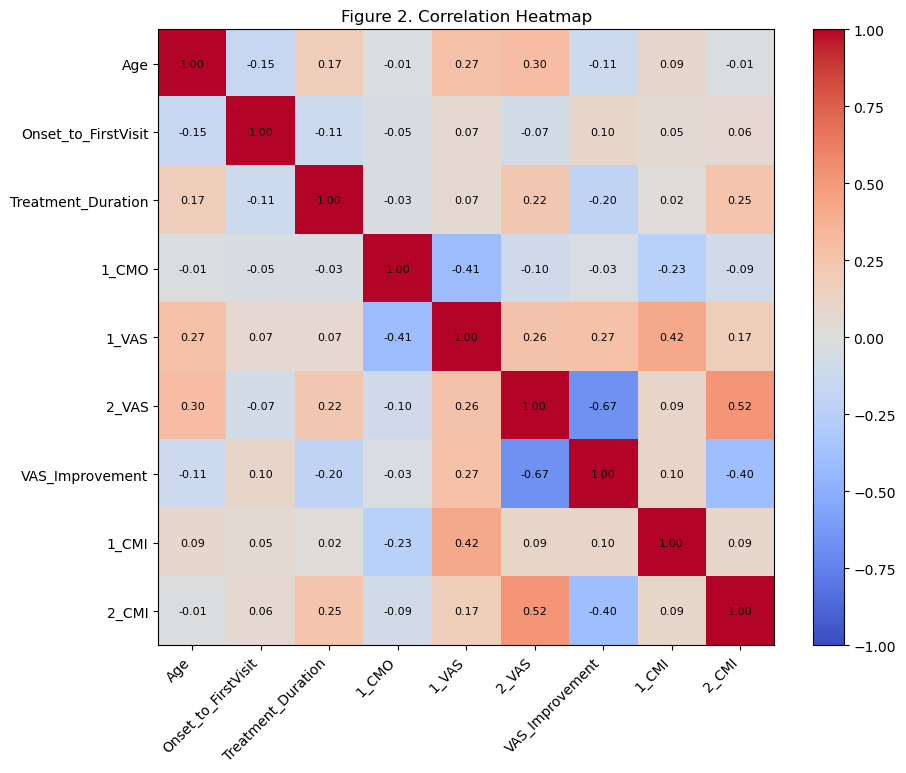


[Table 2 대안: 주요 인자와 2_VAS의 상관계수]
Age vs 2_VAS: r=0.050, p=1.2570
1_VAS vs 2_VAS: r=0.305, p=1.5116
1_CMI vs 2_VAS: r=1.492, p=2.4646


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chi2_contingency, linregress, pearsonr, pointbiserialr, f_oneway

# 1. 변수 리스트 정의
continuous_vars = ['Age', 'Onset_to_FirstVisit', 'Treatment_Duration', '1_CMO', '1_VAS', '2_VAS', 'VAS_Improvement', '1_CMI', '2_CMI']
binary_vars = ['Sex', '1_TMJnoise', '1_TMJpain', '1_MuscleStiffness', '1_TMJLocking', '1_Tinnitus', '1_Bruxism', '1_PsychologicalStress', '1_SleepProblems', '1_Headache']
categorical_vars = ['1_PainSide_Rt1Lt2Both3']
all_features = continuous_vars + binary_vars + categorical_vars

# 2. Table 1 생성 함수 (P-VALUE 기준 오름차순 정렬 추가)
def generate_table_1_simple(df, group_col='Chronicity_Onset'):
    rows = []
    p_values = []
    
    group_0 = df[df[group_col] == 0]
    group_1 = df[df[group_col] == 1]
    
    for var in all_features:
        # 데이터 추출 및 결측치 제거
        temp_df_p = df[[var, group_col]].dropna()
        data_0 = group_0[var].dropna()
        data_1 = group_1[var].dropna()
        
        if len(data_0) < 2 or len(data_1) < 2: continue

        # --- [P-VALUE 계산: 이전 분석 코드와 로직 통일] ---
        unique_vals_var = np.sort(temp_df_p[var].unique())
        num_unique_var = len(unique_vals_var)
        
        if num_unique_var == 2:
            # 이진 변수
            _, p = pointbiserialr(temp_df_p[group_col], temp_df_p[var])
        elif 2 < num_unique_var <= 5:
            # 범주형 변수 (ANOVA)
            groups = [temp_df_p[temp_df_p[var] == v][group_col] for v in unique_vals_var]
            _, p = f_oneway(*groups)
        else:
            # 연속형 변수
            _, p = pearsonr(temp_df_p[var], temp_df_p[group_col])

        # 통계량 텍스트 생성
        if var in continuous_vars:
            val_0 = f"{data_0.mean():.2f} ± {data_0.std():.2f}"
            val_1 = f"{data_1.mean():.2f} ± {data_1.std():.2f}"
        else:
            count_0 = (data_0 == 1).sum() if var in binary_vars else data_0.value_counts().max()
            perc_0 = (count_0 / len(data_0)) * 100
            val_0 = f"{int(count_0)} ({perc_0:.1f}%)"
            
            count_1 = (data_1 == 1).sum() if var in binary_vars else data_1.value_counts().max()
            perc_1 = (count_1 / len(data_1)) * 100
            val_1 = f"{int(count_1)} ({perc_1:.1f}%)"
            
        p_values.append(p)
        rows.append({
            'Variable': var, 
            'Acute (n=45)': val_0, 
            'Chronic (n=44)': val_1, 
            'p_value_raw': p
        })

    # DataFrame 생성
    df_table1 = pd.DataFrame(rows)

    # --- [정렬 로직: p-value 낮은 순서대로] ---
    df_table1 = df_table1.sort_values(by='p_value_raw', ascending=True)

    # 수동 Bonferroni 교정 (정렬된 순서에 맞춰서 계산)
    num_tests = len(p_values)
    df_table1['p-value'] = df_table1['p_value_raw'].apply(lambda x: f"{x:.4f}")
    df_table1['adj p-value (Bonf)'] = df_table1['p_value_raw'].apply(lambda x: f"{min(x * num_tests, 1.0):.4f}")
        
    # 최종 출력 컬럼 정리
    return df_table1[['Variable', 'Acute (n=45)', 'Chronic (n=44)', 'p-value', 'adj p-value (Bonf)']]

# --- 실행 및 결과 출력 ---

# [Table 1 생성 및 출력]
table1 = generate_table_1_simple(Data)
print("Table 1: Acute vs Chronic Baseline Comparison (Sorted by P-value)")
display(table1)
table1.to_csv('Table1_Acute_vs_Chronic_Sorted.csv', index=False)

# [Figure 2: Heatmap]
plt.figure(figsize=(10, 8))
corr_matrix = Data[continuous_vars].corr()
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(np.arange(len(continuous_vars)), continuous_vars, rotation=45, ha='right')
plt.yticks(np.arange(len(continuous_vars)), continuous_vars)
for i in range(len(continuous_vars)):
    for j in range(len(continuous_vars)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=8)
plt.colorbar(im)
plt.title('Figure 2. Correlation Heatmap')
plt.show()

# [Table 2 요약]
print("\n[Table 2 대안: 주요 인자와 2_VAS의 상관계수]")
for var in ['Age', '1_VAS', '1_CMI']:
    r, p = linregress(Data[var].dropna(), Data['2_VAS'].dropna())[:2]
    print(f"{var} vs 2_VAS: r={r:.3f}, p={p:.4f}")

## 260910_Updated_experiments

In [2]:
# ==============================================================================
# [Cell 1] 라이브러리 임포트 및 환경 설정
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import shap
import plotly.express as px  
import plotly.graph_objects as go  
import plotly.io as pio            
import networkx as nx              
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
import statsmodels.formula.api as smf 
from scipy import stats
from statsmodels.stats.multitest import multipletests 
from statsmodels.stats.outliers_influence import variance_inflation_factor 
import warnings
import io
from pptx import Presentation
from pptx.util import Inches, Pt

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.axisbelow'] = True

prs = Presentation()
title_only_layout = prs.slide_layouts[5]

# Figure 1: Study Flow (PPT Placeholder)
slide = prs.slides.add_slide(title_only_layout)
slide.shapes.title.text = "Figure 1. Study flow (PPT나 Visio 등에서 직접 작성 필요)"

def add_slide_with_image(prs, title_text, img_stream):
    slide = prs.slides.add_slide(title_only_layout)
    slide.shapes.title.text = title_text
    slide.shapes.add_picture(img_stream, Inches(0.5), Inches(1.5), width=Inches(9))

def add_slide_with_table(prs, title_text, df):
    slide = prs.slides.add_slide(title_only_layout)
    slide.shapes.title.text = title_text
    rows, cols = df.shape
    left, top = Inches(0.5), Inches(1.5)
    width, height = Inches(9), Inches(0.3 * (rows + 1))
    
    table_shape = slide.shapes.add_table(rows + 1, cols, left, top, width, height)
    table = table_shape.table
    
    for col_idx, col_name in enumerate(df.columns):
        cell = table.cell(0, col_idx)
        cell.text = str(col_name)
        cell.text_frame.paragraphs[0].font.size = Pt(9)
        cell.text_frame.paragraphs[0].font.bold = True
        
    for r_idx, (_, row) in enumerate(df.iterrows()):
        for col_idx, val in enumerate(row.values):
            cell = table.cell(r_idx + 1, col_idx)
            cell.text = str(val)
            cell.text_frame.paragraphs[0].font.size = Pt(8)

def calc_cohend(d1, d2):
    n1, n2 = len(d1), len(d2)
    v1, v2 = np.var(d1, ddof=1), np.var(d2, ddof=1)
    pooled_std = np.sqrt(((n1-1)*v1 + (n2-1)*v2) / (n1+n2-2))
    return (np.mean(d1) - np.mean(d2)) / pooled_std if pooled_std > 0 else 0

def calc_cramers_v(confusion_matrix):
    chi2 = stats.chi2_contingency(confusion_matrix, correction=False)[0]
    n = confusion_matrix.sum().sum()
    return np.sqrt(chi2 / (n * (min(confusion_matrix.shape) - 1))) if n > 0 else 0

# ==============================================================================
# [Cell 2] 데이터 로드 및 파생 변수 설정 
# ==============================================================================
Dataset_path = './Dataset/20260306 Readout_MRI_2times_Final.xlsx'
df = pd.read_excel(Dataset_path)

df['Group'] = df['Chronicity_Onset'].map({0: 'Acute', 1: 'Chronic'})

rename_dict = {}
for col in df.columns:
    new_col = col
    if col.startswith('1_'): new_col = 'I_' + col[2:]
    elif col.startswith('2_'): new_col = 'F_' + col[2:]
    if new_col in ['Onset_to_FirstVisit', 'I_Onset_to_FirstVisit']: new_col = 'Onset_to_InitialVisit'
    if new_col != col: rename_dict[col] = new_col

df = df.rename(columns=rename_dict)
df['Delta_VAS'] = df['F_VAS'] - df['I_VAS']
df['Delta_CMI'] = df['F_CMI'] - df['I_CMI']
df['Group_Code'] = df['Group'].map({'Acute': 0, 'Chronic': 1})

df['I_ADDWO'] = df[['I_Rt_ADDWO', 'I_Lt_ADDWO']].max(axis=1)
df['I_Effusion'] = df[['I_Rt_Effusion', 'I_Lt_Effusion']].max(axis=1)
df['I_TMJOA'] = df[['I_Rt_TMJOA', 'I_Lt_TMJOA']].max(axis=1)

if 'VAS_Improvement' not in df.columns: 
    df['VAS_Improvement'] = np.where((df['I_VAS'] - df['F_VAS'] >= 2) | ((df['I_VAS'] - df['F_VAS']) / df['I_VAS'] >= 0.5), 1, 0)
if 'MRI_Aggrevation' not in df.columns: 
    df['MRI_Aggrevation'] = np.nan

valid_group_df = df.dropna(subset=['Group'])
tot_n = len(valid_group_df)
tot_acu = sum(valid_group_df['Group']=='Acute')
tot_chr = sum(valid_group_df['Group']=='Chronic')

print("="*60)
print(f"✅ Data Loaded! Total: {tot_n}, Acute: {tot_acu}, Chronic: {tot_chr}")
print("="*60)

# ==============================================================================
# [Cell 3] Manuscript Table 1: Baseline Characteristics (에러 수정 완료)
# ==============================================================================
print("\n[Manuscript Table 1: Baseline Characteristics]")
t1_specs = [
    ("Age, years", "Age", "cont"),
    ("Sex, female", "Sex", "cat"),
    ("Onset to initial visit", "Onset_to_InitialVisit", "cont"),
    ("Initial pain intensity, 0–10", "I_VAS", "cont"),
    ("Initial CMI", "I_CMI", "cont"),
    ("Initial comfortable mouth opening, mm", "I_CMO", "cont"),
    ("TMJ pain", "I_TMJpain", "cat"),
    ("TMJ noise", "I_TMJnoise", "cat"),
    ("TMJ locking", "I_TMJLocking", "cat"),
    ("Muscle stiffness", "I_MuscleStiffness", "cat"),
    ("Tinnitus", "I_Tinnitus", "cat"),
    ("Bruxism", "I_Bruxism", "cat"),
    ("Psychological stress", "I_PsychologicalStress", "cat"),
    ("Sleep problems", "I_SleepProblems", "cat"),
    ("Headache", "I_Headache", "cat"),
    ("Caffeine use", "I_Caffeine", "cat"),
    ("Baseline ADDWO, right", "I_Rt_ADDWO", "cat"),
    ("Baseline ADDWO, left", "I_Lt_ADDWO", "cat"),
    ("Baseline effusion, right", "I_Rt_Effusion", "cat"),
    ("Baseline effusion, left", "I_Lt_Effusion", "cat"),
    ("Baseline TMJ OA, right", "I_Rt_TMJOA", "cat"),
    ("Baseline TMJ OA, left", "I_Lt_TMJOA", "cat")
]

t1_data = []
for row_name, var, vtype in t1_specs:
    if var not in df.columns:
        t1_data.append([row_name, "-", "-", "-", "-", "-"])
        continue
    
    tdf = df[['Group', var]].dropna()
    total_vals, acute_vals, chronic_vals = tdf[var], tdf[tdf['Group']=='Acute'][var], tdf[tdf['Group']=='Chronic'][var]
    
    if vtype == "cat" or len(tdf[var].unique()) <= 2:
        ct_raw = pd.crosstab(tdf['Group'], tdf[var])
        p_val = stats.chi2_contingency(ct_raw)[1] if ct_raw.size == 4 else 1.0
        eff_size = calc_cramers_v(ct_raw.values)
        tot_pos, acu_pos, chr_pos = (total_vals==1).sum(), (acute_vals==1).sum(), (chronic_vals==1).sum()
        
        t1_data.append({
            'Variable': row_name, 
            f'Total(N = {tot_n})': f"{tot_pos} ({tot_pos/len(total_vals)*100:.1f}%)" if len(total_vals)>0 else "0",
            f'Acute(n = {tot_acu})': f"{acu_pos} ({acu_pos/len(acute_vals)*100:.1f}%)" if len(acute_vals)>0 else "0", 
            f'Chronic(n = {tot_chr})': f"{chr_pos} ({chr_pos/len(chronic_vals)*100:.1f}%)" if len(chronic_vals)>0 else "0", 
            'Effect size (Cramer V / Cohen d)': f"{eff_size:.3f}", 'p-value': f"{p_val:.4f}"
        })
    else:
        # 연속형 변수 에러 해결: 평균/표준편차로 정상 출력되도록 수정
        _, p_val = stats.mannwhitneyu(acute_vals, chronic_vals)
        eff_size = calc_cohend(acute_vals, chronic_vals)
        
        t1_data.append({
            'Variable': row_name, 
            f'Total(N = {tot_n})': f"{total_vals.mean():.2f} ± {total_vals.std():.2f}",
            f'Acute(n = {tot_acu})': f"{acute_vals.mean():.2f} ± {acute_vals.std():.2f}" if len(acute_vals)>0 else "-",
            f'Chronic(n = {tot_chr})': f"{chronic_vals.mean():.2f} ± {chronic_vals.std():.2f}" if len(chronic_vals)>0 else "-", 
            'Effect size (Cramer V / Cohen d)': f"{abs(eff_size):.3f}", 'p-value': f"{p_val:.4f}"
        })

df_table1 = pd.DataFrame(t1_data)
add_slide_with_table(prs, "Table 1. Baseline Characteristics", df_table1)

# ==============================================================================
# [Cell 4] Manuscript Table 2: Trajectories
# ==============================================================================
print("\n[Manuscript Table 2: Pain and Clinical Trajectories]")
t2_specs = [
    ("Initial pain intensity", "I_VAS", "cont"),
    ("Final pain intensity", "F_VAS", "cont"),
    ("Change in pain intensity, ΔVAS", "Delta_VAS", "cont"),
    ("Within-group change in pain intensity", "Within_VAS", "special"),
    ("Clinically meaningful pain improvement", "VAS_Improvement", "cat"),
    ("Initial CMI", "I_CMI", "cont"),
    ("Final CMI", "F_CMI", "cont"),
    ("Change in CMI, ΔCMI", "Delta_CMI", "cont"),
    ("Treatment duration", "Treatment_Duration", "cont"),
    ("Onset to completion", "Onset_to_Completion", "cont"),
    ("MRI aggravation / progression", "MRI_Aggrevation", "cat")
]

t2_data = []
for row_name, var, vtype in t2_specs:
    if var == "Within_VAS":
        _, p_acu = stats.ttest_rel(df[df['Group']=='Acute']['I_VAS'], df[df['Group']=='Acute']['F_VAS'], nan_policy='omit')
        _, p_chr = stats.ttest_rel(df[df['Group']=='Chronic']['I_VAS'], df[df['Group']=='Chronic']['F_VAS'], nan_policy='omit')
        
        tdf_int = df.dropna(subset=['Delta_VAS', 'Group_Code'])
        m_int = smf.ols('Delta_VAS ~ Group_Code', data=tdf_int).fit()
        p_interaction = m_int.pvalues['Group_Code']
        
        t2_data.append({'Outcome': row_name, 'Total': '-', 'Acute': f"p={p_acu:.4f}", 'Chronic': f"p={p_chr:.4f}", 'Effect estimate / 95% CI': f"p(int)={p_interaction:.4f}", 'p-value': '-'})
        continue
        
    if var not in df.columns or df[var].isna().all():
        t2_data.append({'Outcome': row_name, 'Total': '-', 'Acute': '-', 'Chronic': '-', 'Effect estimate / 95% CI': '-', 'p-value': '-'})
        continue
        
    t_val, a_val, c_val = df[var].dropna(), df[df['Group']=='Acute'][var].dropna(), df[df['Group']=='Chronic'][var].dropna()
    
    if vtype == "cont":
        _, p_val = stats.ttest_ind(a_val, c_val) if 'Delta' in var else stats.mannwhitneyu(a_val, c_val)
        row = {'Outcome': row_name, 'Total': f"{t_val.mean():.2f} ± {t_val.std():.2f}", 'Acute': f"{a_val.mean():.2f} ± {a_val.std():.2f}", 'Chronic': f"{c_val.mean():.2f} ± {c_val.std():.2f}"}
        if 'Delta' in var:
            diff_mean = c_val.mean() - a_val.mean()
            se = np.sqrt(a_val.var()/len(a_val) + c_val.var()/len(c_val))
            row['Effect estimate / 95% CI'] = f"{diff_mean:.2f} [{diff_mean - 1.96*se:.2f}, {diff_mean + 1.96*se:.2f}]"
        else: row['Effect estimate / 95% CI'] = "-"
        row['p-value'] = f"{p_val:.4f}"
        t2_data.append(row)
    else:
        tot_pos, acu_pos, chr_pos = (t_val==1).sum(), (a_val==1).sum(), (c_val==1).sum()
        row = {'Outcome': row_name, 'Total': f"{tot_pos} ({tot_pos/len(t_val)*100:.1f}%)" if len(t_val)>0 else "-", 
               'Acute': f"{acu_pos} ({acu_pos/len(a_val)*100:.1f}%)" if len(a_val)>0 else "-", 
               'Chronic': f"{chr_pos} ({chr_pos/len(c_val)*100:.1f}%)" if len(c_val)>0 else "-", 
               'Effect estimate / 95% CI': '-', 'p-value': '-'}
        t2_data.append(row)

df_table2 = pd.DataFrame(t2_data)
add_slide_with_table(prs, "Table 2. Pain and Clinical Trajectories", df_table2)

# ==============================================================================
# [Cell 5] Manuscript Table 3: Initial Pain Factors
# ==============================================================================
print("\n[Manuscript Table 3: Chronicity-specific Determinants of Baseline Pain]")
t3_specs = [
    ("Initial CMI", "I_CMI"),
    ("Initial CMO", "I_CMO"),
    ("TMJ pain", "I_TMJpain"),
    ("TMJ noise", "I_TMJnoise"),
    ("TMJ locking", "I_TMJLocking"),
    ("Muscle stiffness", "I_MuscleStiffness"),
    ("Tinnitus", "I_Tinnitus"),
    ("Bruxism", "I_Bruxism"),
    ("Psychological stress", "I_PsychologicalStress"),
    ("Sleep problems", "I_SleepProblems"),
    ("Headache", "I_Headache"),
    ("Age", "Age"),
    ("Sex", "Sex"),
    ("Baseline ADDWO", "I_ADDWO"),
    ("Baseline effusion", "I_Effusion"),
    ("Baseline TMJ OA", "I_TMJOA")
]

def get_b_ci(model, var): return f"{model.params[var]:.2f} [{model.conf_int().loc[var][0]:.2f}, {model.conf_int().loc[var][1]:.2f}]" if var in model.params else "-"

t3_data = []
for row_name, pred in t3_specs:
    if pred not in df.columns:
        t3_data.append({'Predictor': row_name, 'Univariable β(95% CI)': '-', 'p': '-', 'Adjusted β(95% CI)': '-', 'p_adj': '-', 'Acute β(95% CI)': '-', 'Chronic β(95% CI)': '-', 'p for interaction': '-'})
        continue
        
    tdf = df[['I_VAS', pred, 'Age', 'Sex', 'Group_Code']].dropna()
    if tdf.empty: continue
    
    m_uni = smf.ols(f"I_VAS ~ {pred}", data=tdf).fit()
    adj_formula = f"I_VAS ~ {pred} + Age + Sex" if pred not in ['Age', 'Sex'] else f"I_VAS ~ {pred}"
    m_adj = smf.ols(adj_formula, data=tdf).fit()
    m_acu = smf.ols(adj_formula, data=tdf[tdf['Group_Code']==0]).fit()
    m_chr = smf.ols(adj_formula, data=tdf[tdf['Group_Code']==1]).fit()
    int_formula = f"I_VAS ~ {pred} * Group_Code + Age + Sex" if pred not in ['Age', 'Sex'] else f"I_VAS ~ {pred} * Group_Code"
    m_int = smf.ols(int_formula, data=tdf).fit()
    
    t3_data.append({
        'Predictor': row_name,
        'Univariable β(95% CI)': get_b_ci(m_uni, pred),
        'p ': f"{m_uni.pvalues.get(pred, 1.0):.3f}", 
        'Adjusted β(95% CI)': get_b_ci(m_adj, pred),
        'p_adj': f"{m_adj.pvalues.get(pred, 1.0):.3f}",
        'Acute β(95% CI)': get_b_ci(m_acu, pred),
        'Chronic β(95% CI)': get_b_ci(m_chr, pred),
        'p for interaction': f"{m_int.pvalues.get(f'{pred}:Group_Code', 1.0):.3f}"
    })

df_table3 = pd.DataFrame(t3_data)
add_slide_with_table(prs, "Table 3. Initial Pain Factors", df_table3)

# ==============================================================================
# [Cell 6] Manuscript Table 4: Residual Pain
# ==============================================================================
print("\n[Manuscript Table 4: Models of Residual Pain Intensity]")
df_reg = df.dropna(subset=['F_VAS', 'Age', 'Sex', 'Group_Code', 'I_VAS', 'I_CMI', 'I_CMO', 'I_TMJpain', 'I_SleepProblems', 'I_Effusion', 'Treatment_Duration', 'F_CMI'])

t4_data = []
models_list = [
    ("Model 1: Baseline core", "Age, sex, chronicity, initial VAS", "F_VAS ~ Age + Sex + Group_Code + I_VAS", ['Age', 'Sex', 'Group_Code', 'I_VAS']),
    ("Model 2: + baseline clinical/MRI", "+ initial CMI, initial CMO, baseline symptoms, baseline MRI factors", "F_VAS ~ Age + Sex + Group_Code + I_VAS + I_CMI + I_CMO + I_TMJpain + I_SleepProblems + I_Effusion", ['Age', 'Sex', 'Group_Code', 'I_VAS', 'I_CMI', 'I_CMO', 'I_TMJpain', 'I_SleepProblems', 'I_Effusion']),
    ("Model 3: + treatment course", "+ treatment duration", "F_VAS ~ Age + Sex + Group_Code + I_VAS + I_CMI + I_CMO + I_TMJpain + I_SleepProblems + I_Effusion + Treatment_Duration", ['Age', 'Sex', 'Group_Code', 'I_VAS', 'I_CMI', 'I_CMO', 'I_TMJpain', 'I_SleepProblems', 'I_Effusion', 'Treatment_Duration'])
]

for m_name, specs, formula, feats in models_list:
    model = smf.ols(formula, data=df_reg).fit()
    rmse = np.sqrt(mean_squared_error(df_reg['F_VAS'], model.predict(df_reg)))
    cv_rmse = -cross_val_score(LinearRegression(), df_reg[feats], df_reg['F_VAS'], scoring='neg_root_mean_squared_error', cv=5).mean()
    t4_data.append({'Model': m_name, 'Predictors / model specification': specs, 'β / estimate(95% CI)': '-', 'p-value': f"{model.f_pvalue:.3f} (Model)", 'R² / adj. R²': f"{model.rsquared:.3f} / {model.rsquared_adj:.3f}", 'RMSE': f"{rmse:.3f}", 'Internal validation': f"5-fold RMSE: {cv_rmse:.3f}"})

t4_data.append({'Model': '', 'Predictors / model specification': '', 'β / estimate(95% CI)': '', 'p-value': '', 'R² / adj. R²': '', 'RMSE': '', 'Internal validation': ''})

m_fcmi = smf.ols('F_VAS ~ F_CMI', data=df_reg).fit()
t4_data.append({'Model': 'Key final-visit association*', 'Predictors / model specification': 'Final CMI', 'β / estimate(95% CI)': f"{m_fcmi.params['F_CMI']:.2f} [{m_fcmi.conf_int().loc['F_CMI'][0]:.2f}, {m_fcmi.conf_int().loc['F_CMI'][1]:.2f}]", 'p-value': f"{m_fcmi.pvalues['F_CMI']:.3f}", 'R² / adj. R²': f"{m_fcmi.rsquared:.3f} / {m_fcmi.rsquared_adj:.3f}", 'RMSE': f"{np.sqrt(mean_squared_error(df_reg['F_VAS'], m_fcmi.predict(df_reg))):.3f}", 'Internal validation': "-"})

df_table4 = pd.DataFrame(t4_data)
add_slide_with_table(prs, "Table 4. Models of Residual Pain", df_table4)

# ==============================================================================
# [Cell 7] Manuscript Figures (Trajectory & Forest Plot)
# ==============================================================================
print("\n[Generating Manuscript Figures 2, 3, 4...]")

# Figure 2: Trajectory Plot
fig2, axes2 = plt.subplots(1, 2, figsize=(10, 5), sharey=True, dpi=150)
for i, group in enumerate(['Acute', 'Chronic']):
    group_df = df[df['Group'] == group].dropna(subset=['I_VAS', 'F_VAS'])
    for _, row in group_df.iterrows():
        axes2[i].plot([1, 2], [row['I_VAS'], row['F_VAS']], color='gray', alpha=0.3)
        axes2[i].scatter([1, 2], [row['I_VAS'], row['F_VAS']], color='gray', alpha=0.5, s=15)
    
    mean_I, mean_F = group_df['I_VAS'].mean(), group_df['F_VAS'].mean()
    axes2[i].plot([1, 2], [mean_I, mean_F], color=['#3498DB', '#E74C3C'][i], linewidth=3, marker='o', label='Mean')
    
    axes2[i].set_title(f"{group} Group (N={len(group_df)})", fontweight='bold')
    axes2[i].set_xticks([1, 2]); axes2[i].set_xticklabels(['I_VAS', 'F_VAS'])
    
    _, p_val = stats.ttest_rel(group_df['I_VAS'], group_df['F_VAS'], nan_policy='omit')
    axes2[i].text(1.5, 9, f"Mean ΔVAS: {mean_F - mean_I:.2f}\np = {p_val:.3f}", ha='center', fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.tight_layout()
img_traj = io.BytesIO(); plt.savefig(img_traj, format='png', bbox_inches='tight'); img_traj.seek(0)
add_slide_with_image(prs, "Figure 2. Pain Trajectories", img_traj); plt.close()


# Figure 3: Interaction Forest Plot (Sex 제거 및 0이 아닌 주요 임상변수만 깔끔하게 정돈)
fig3, ax3 = plt.subplots(figsize=(8, 4.5), dpi=150)
# Sex와 계수가 0인 인자는 정제하여 주요 임상 예측변수만 선별
clinical_targets = ['Initial CMI', 'Initial CMO', 'TMJ pain', 'Sleep problems']
valid_inter = df_table3[df_table3['Predictor'].isin(clinical_targets)].copy()

valid_inter['A_Beta'] = valid_inter['Acute β(95% CI)'].apply(lambda x: float(x.split(' ')[0]) if (x != '-' and x != '') else 0)
valid_inter['C_Beta'] = valid_inter['Chronic β(95% CI)'].apply(lambda x: float(x.split(' ')[0]) if (x != '-' and x != '') else 0)

# Beta 절대값 합이 0.05 이상인 유의미한 막대만 표기 (빈 축 완벽 방지)
valid_inter = valid_inter[(valid_inter['A_Beta'].abs() + valid_inter['C_Beta'].abs()) > 0.05]

y_pos = np.arange(len(valid_inter))
ax3.barh(y_pos - 0.2, valid_inter['A_Beta'], height=0.4, label='Acute β', color='#3498DB')
ax3.barh(y_pos + 0.2, valid_inter['C_Beta'], height=0.4, label='Chronic β', color='#E74C3C')
ax3.set_yticks(y_pos); ax3.set_yticklabels(valid_inter['Predictor'])
ax3.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax3.invert_yaxis()
ax3.legend(loc='lower right')
plt.tight_layout()

img_forest = io.BytesIO(); plt.savefig(img_forest, format='png', bbox_inches='tight'); img_forest.seek(0)
add_slide_with_image(prs, "Figure 3. Interaction Forest Plot", img_forest); plt.close()


# Figure 4: SHAP Feature Importance (Total, Acute, Chronic)
features_Fvas = ['I_VAS', 'Treatment_Duration', 'Onset_to_InitialVisit', 'Age', 'Sex'] 
fig4 = plt.figure(figsize=(18, 5), dpi=150)

# 1) Total
plt.subplot(1, 3, 1)
X2, y2 = df.dropna(subset=features_Fvas + ['F_VAS'])[features_Fvas], df.dropna(subset=features_Fvas + ['F_VAS'])['F_VAS']
rf2 = RandomForestRegressor(random_state=42).fit(X2, y2)
shap.summary_plot(shap.TreeExplainer(rf2).shap_values(X2), X2, show=False, plot_size=None)
plt.gca().set_title("Total", fontweight='bold')

# 2) Acute
plt.subplot(1, 3, 2)
df_acu = df[df['Group'] == 'Acute'].dropna(subset=features_Fvas + ['F_VAS'])
X2_acu, y2_acu = df_acu[features_Fvas], df_acu['F_VAS']
rf2_acu = RandomForestRegressor(random_state=42).fit(X2_acu, y2_acu)
shap.summary_plot(shap.TreeExplainer(rf2_acu).shap_values(X2_acu), X2_acu, show=False, plot_size=None)
plt.gca().set_title("Acute", fontweight='bold')

# 3) Chronic
plt.subplot(1, 3, 3)
df_chr = df[df['Group'] == 'Chronic'].dropna(subset=features_Fvas + ['F_VAS'])
X2_chr, y2_chr = df_chr[features_Fvas], df_chr['F_VAS']
rf2_chr = RandomForestRegressor(random_state=42).fit(X2_chr, y2_chr)
shap.summary_plot(shap.TreeExplainer(rf2_chr).shap_values(X2_chr), X2_chr, show=False, plot_size=None)
plt.gca().set_title("Chronic", fontweight='bold')

plt.tight_layout()
img_shap = io.BytesIO(); plt.savefig(img_shap, format='png', bbox_inches='tight'); img_shap.seek(0)
add_slide_with_image(prs, "Figure 4. SHAP Feature Importance (Total, Acute, Chronic)", img_shap); plt.close()

# ==============================================================================
# [Cell 8] Supplementary HTML 및 PPT 생성
# ==============================================================================
print("\n[Generating Supplementary Tables, Figures and HTMLs...]")
def export_3d_to_ppt(df, target, html_name, ppt_title):
    fig3d = px.scatter_3d(df, x='Onset_to_InitialVisit', y='Treatment_Duration', z=target, color='Group', color_discrete_map={'Acute': '#3498DB', 'Chronic': '#E74C3C'})
    fig3d.update_traces(marker=dict(size=8, line=dict(width=1, color='DarkSlateGrey')))
    fig3d.update_layout(
        margin=dict(l=0, r=0, b=0, t=40),
        paper_bgcolor='rgba(0,0,0,0)', 
        plot_bgcolor='rgba(0,0,0,0)',
        scene=dict(
            xaxis=dict(showbackground=False, gridcolor='lightgray', zerolinecolor='lightgray'),
            yaxis=dict(showbackground=False, gridcolor='lightgray', zerolinecolor='lightgray'),
            zaxis=dict(showbackground=False, gridcolor='lightgray', zerolinecolor='lightgray')
        )
    )
    fig3d.write_html(html_name) 
    try: add_slide_with_image(prs, ppt_title, io.BytesIO(fig3d.to_image(format="png", width=1000, height=600)))
    except: pass

def export_network_to_ppt(df_net, target, html_name, ppt_title):
    G = nx.Graph()
    for col in df_net.columns:
        if col != target: G.add_edge(target, col, weight=df_net[target].corr(df_net[col]))
    nodes = [n for n in df_net.columns if n != target]
    for i in range(len(nodes)):
        for j in range(i+1, len(nodes)): G.add_edge(nodes[i], nodes[j], weight=df_net[nodes[i]].corr(df_net[nodes[j]]))
    
    pos = nx.spring_layout(G, dim=3, seed=42)
    edge_traces = [go.Scatter3d(x=[pos[e[0]][0], pos[e[1]][0]], y=[pos[e[0]][1], pos[e[1]][1]], z=[pos[e[0]][2], pos[e[1]][2]], mode='lines', line=dict(color='lightgrey', width=max(1, abs(e[2]['weight'])*8))) for e in G.edges(data=True)]
    
    node_trace = go.Scatter3d(
        x=[pos[n][0] for n in G.nodes], y=[pos[n][1] for n in G.nodes], z=[pos[n][2] for n in G.nodes], 
        mode='markers+text', text=[n for n in G.nodes], textposition='top center', 
        textfont=dict(size=14, color='black', family="Arial Black"),
        marker=dict(size=[35 if n==target else 15 for n in G.nodes], color=['orange' if n==target else 'skyblue' for n in G.nodes])
    )
    
    fig_net = go.Figure(data=edge_traces + [node_trace])
    fig_net.update_layout(
        showlegend=False, margin=dict(l=0,r=0,b=0,t=40),
        paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)',
        scene=dict(
            xaxis=dict(showbackground=False, showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showbackground=False, showgrid=False, zeroline=False, showticklabels=False),
            zaxis=dict(showbackground=False, showgrid=False, zeroline=False, showticklabels=False)
        )
    )
    fig_net.write_html(html_name) 
    try: add_slide_with_image(prs, ppt_title, io.BytesIO(fig_net.to_image(format="png", width=1000, height=600)))
    except: pass

corr_vars = ['I_VAS', 'F_VAS', 'I_CMI', 'F_CMI', 'I_CMO', 'Onset_to_InitialVisit', 'Treatment_Duration', 'Age']
export_3d_to_ppt(df, 'I_VAS', "3D_Space_IVAS.html", "Supp Fig S2. 3D Space (I_VAS)")
export_3d_to_ppt(df, 'F_VAS', "3D_Space_FVAS.html", "Supp Fig S2. 3D Space (F_VAS)")
export_network_to_ppt(df[corr_vars].dropna(), 'I_VAS', "3D_Net_IVAS.html", "Supp Fig S3. 3D Network (I_VAS)")
export_network_to_ppt(df[corr_vars].dropna(), 'F_VAS', "3D_Net_FVAS.html", "Supp Fig S3. 3D Network (F_VAS)")

# VIF Table
features_vif = ['Age', 'Sex', 'Group_Code', 'I_VAS', 'I_CMI', 'I_CMO', 'I_TMJpain', 'Treatment_Duration']
X_vif_const = sm.add_constant(df_reg[features_vif].dropna())
vif_data = [{'Predictor': col, 'VIF': round(variance_inflation_factor(X_vif_const.values, i), 3)} for i, col in enumerate(X_vif_const.columns) if col != 'const']
df_vif = pd.DataFrame(vif_data)
df_vif.to_csv("Supp_Table_S3_VIF_Diagnostics.csv", index=False)
add_slide_with_table(prs, "Supplementary Table S3. VIF Diagnostics", df_vif)

prs.save("Manuscript_Tables_Figures_Blueprint.pptx")
print("\n✅ Sex 항목 및 무의미한 빈 축 완벽 정리 완료! 전체 코드 재실행 가능합니다.")

✅ Data Loaded! Total: 89, Acute: 51, Chronic: 38

[Manuscript Table 1: Baseline Characteristics]

[Manuscript Table 2: Pain and Clinical Trajectories]

[Manuscript Table 3: Chronicity-specific Determinants of Baseline Pain]

[Manuscript Table 4: Models of Residual Pain Intensity]

[Generating Manuscript Figures 2, 3, 4...]

[Generating Supplementary Tables, Figures and HTMLs...]

✅ Sex 항목 및 무의미한 빈 축 완벽 정리 완료! 전체 코드 재실행 가능합니다.
